In [15]:
import numpy as np
import pandas as pd
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected = True)
#import matplotlib.pyplot as plt
#import plotly.figure_factory as ff
import plotly.plotly as py

%matplotlib inline
import numpy as np
import pandas as pd
import plotly.plotly as py
import plotly.graph_objs as go
import matplotlib.pyplot as plt
import plotly.figure_factory as ff

from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

init_notebook_mode(connected=True)

#import plotly
import plotly.offline as py

from IPython.core.pylabtools import figsize

In [18]:
df = pd.read_csv('Meteorologia.csv',encoding='utf-8')
df.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4297 entries, 0 to 4296
Data columns (total 15 columns):
data                       4297 non-null object
deficit_vapor_vmin         4297 non-null float64
deficit_vapor_vmedio       4297 non-null float64
ponto_orvalho_vmin         4297 non-null float64
ponto_orvalho_vmedio       4297 non-null float64
precipitacao_valor         4297 non-null float64
radiacao_solar_valor       4297 non-null float64
temperatura_ar_vmin        4297 non-null float64
temperatura_ar_vmedio      4297 non-null float64
temperatura_ar_vmax        4297 non-null float64
umidade_ar_vmin            4297 non-null float64
umidade_ar_vmedio          4297 non-null float64
umidade_ar_vmax            4297 non-null float64
velocidade_vento_vmedio    4297 non-null float64
velocidade_vento_vmax      4297 non-null float64
dtypes: float64(14), object(1)
memory usage: 503.6+ KB


In [65]:
df.isin({0}).sum()

data                          0
deficit_vapor_vmin            0
deficit_vapor_vmedio          0
ponto_orvalho_vmin            0
ponto_orvalho_vmedio          0
precipitacao_valor         4147
radiacao_solar_valor       2405
temperatura_ar_vmin           0
temperatura_ar_vmedio         0
temperatura_ar_vmax           0
umidade_ar_vmin               0
umidade_ar_vmedio             0
umidade_ar_vmax               0
velocidade_vento_vmedio    1610
velocidade_vento_vmax      1409
dtype: int64

In [66]:
a = df.groupby('radiacao_solar_valor').size()
a.head()

radiacao_solar_valor
0.0     2405
10.0      26
11.0       8
12.0       2
13.0       4
dtype: int64

In [67]:
#df.data.dtype

In [68]:
#df.data = pd.to_datetime(df.data)
#df.data.dtype

In [23]:
df['dia'] = pd.to_datetime(df['data']).dt.date
df.head()
#df['data'] = df['data'].dt.strftime('%d/%m/%Y')
#df
df['hora'] = pd.to_datetime(df['data']).dt.hour
df.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax,dia,hora
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0,2018-09-30,23
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5,2018-09-30,23
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1,2018-09-30,23
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1,2018-09-30,23
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0,2018-09-30,23


In [85]:
df['hora'] = [d.time() for d in df['data']]
df

AttributeError: 'str' object has no attribute 'time'

In [86]:
df['hora'] = df['data'].dt.hour
df

AttributeError: Can only use .dt accessor with datetimelike values

In [24]:
#b = df.groupby('data').temperatura_ar_vmedio.mean()
temp = pd.DataFrame(df.groupby('dia').temperatura_ar_vmedio.mean()).reset_index()
temp


,dia,temperatura_ar_vmedio
0,2018-09-01,23.413986
1,2018-09-02,23.829161
2,2018-09-03,18.007552
3,2018-09-04,13.846643
4,2018-09-05,14.679510
5,2018-09-06,16.898889
6,2018-09-07,19.353986
7,2018-09-08,20.933007
8,2018-09-09,18.788671
9,2018-09-10,19.592867


In [7]:
plt.plot(b)
plt.show

NameError: name 'b' is not defined

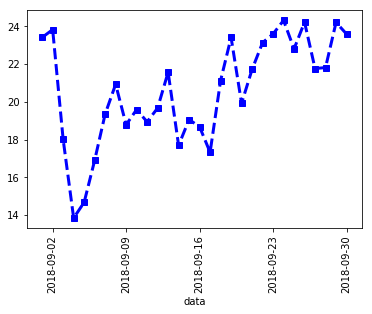

In [72]:
ax = b.plot(rot=90, linestyle='--', color='b', marker='s', 
         linewidth=3.0)
#ax.set_xticks((1,30))
#ax.axis([0,24,0,29])
plt.show()

In [26]:
trace = go.Scatter(x=temp['dia'],y=temp['temperatura_ar_vmedio'],mode = 'lines+markers')
data = [trace]
layout = go.Layout(
    title='Temperatura do ar em Setembro',
    xaxis=dict(title='Data',titlefont=dict(size=20),tickangle=35),
    yaxis=dict(title='Temperatura',titlefont=dict(size=20)))
py.iplot(go.Figure(data = [trace], layout=layout))

In [ ]:
trace1 = go.Scatter(
    y=temp['temperatura_ar_vmedio'],
    x=df.data
)
data = [trace1]

py.iplot(data)

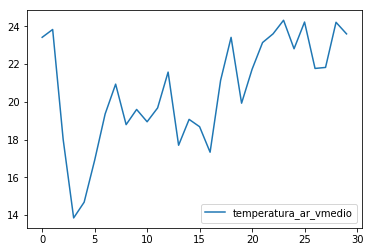

In [35]:
temp.plot();